# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 9: Comparison of Defuzzification Methods**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To apply and compare basic defuzzification methods such as Centroid, Bisector, and Mean of Maximum using Python.

### 2. Theory: Defuzzification Methodologies

Defuzzification reduces an aggregated fuzzy membership distribution $\mu(y)$ into a crisp representative value $y^*$.

#### 1. Centroid Method (Center of Gravity, COG):
The physical center of mass of the area:
$$y_{\text{COG}}^* = \frac{\int y \cdot \mu(y) \, dy}{\int \mu(y) \, dy}$$

#### 2. Bisector Method:
The vertical dividing boundary splitting the area into two identical halves:
$$\int_{y_{\min}}^{y_{\text{Bisector}}^*} \mu(y) \, dy = \int_{y_{\text{Bisector}}^*}^{y_{\max}} \mu(y) \, dy$$

#### 3. Maximum-Based Methods (MOM, SOM, LOM):
Given the set of peak elements $M = \{y \mid \mu(y) = \max_u \mu(u)\}$:
- **Mean of Maximum (MOM):** Average of peak points $y_{\text{MOM}}^* = \frac{1}{|M|} \sum_{y \in M} y$
- **Smallest of Maximum (SOM):** Leftmost peak point $y_{\text{SOM}}^* = \min(M)$
- **Largest of Maximum (LOM):** Rightmost peak point $y_{\text{LOM}}^* = \max(M)$

### 3. Step 1: Synthesizing an Asymmetric Bimodal Distribution Over Risk Domain

#### What this cell does:
We construct an asymmetric fuzzy distribution over Risk Score $y \in [0, 50]$ with 1000 points, simulating the aggregation of a low-priority broad trapezoid and a high-priority sharp triangle:
$$\mu_{\text{risk}}(y) = \max\Big(\min(0.5, \text{trapmf}(y; [5, 12, 22, 32])), \min(0.85, \text{trimf}(y; [24, 38, 48]))\Big)$$

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universe: Risk Score [0, 50]
y_domain = np.linspace(0, 50, 1000)

# Build bimodal fuzzy set
trap_comp = np.minimum(0.5, fuzz.trapmf(y_domain, [5, 12, 22, 32]))
tri_comp = np.minimum(0.85, fuzz.trimf(y_domain, [24, 38, 48]))

fuzzy_risk = np.maximum(trap_comp, tri_comp)

print("Asymmetric fuzzy risk distribution synthesized successfully.")
print(f"Max membership value: {np.max(fuzzy_risk):.3f}")


Asymmetric fuzzy risk distribution synthesized successfully.
Max membership value: 0.850


### 4. Step 2: Evaluating All Five Defuzzification Methods

#### What this cell does:
We compute Centroid, Bisector, MOM, SOM, and LOM, comparing mathematical definitions and numerical values.

In [2]:
defuzz_strat = ['centroid', 'bisector', 'mom', 'som', 'lom']
results = {}

for strat in defuzz_strat:
    results[strat] = fuzz.defuzz(y_domain, fuzzy_risk, strat)

print("=" * 66)
print("             DEFUZZIFICATION STRATEGY COMPARISON AUDIT")
print("=" * 66)
print(f"{'Method':<20} | {'Focus':<22} | {'Value y*':<16}")
print("-" * 66)
print(f"{'Centroid (COG)':<20} | {'Center of Mass':<22} | {results['centroid']:>12.4f}")
print(f"{'Bisector':<20} | {'Equal Area Divider':<22} | {results['bisector']:>12.4f}")
print(f"{'Mean of Max (MOM)':<20} | {'Peak Plateau Center':<22} | {results['mom']:>12.4f}")
print(f"{'Smallest of Max (SOM)':<20} | {'Leftmost Peak Point':<22} | {results['som']:>12.4f}")
print(f"{'Largest of Max (LOM)':<20} | {'Rightmost Peak Point':<22} | {results['lom']:>12.4f}")
print("=" * 66)


             DEFUZZIFICATION STRATEGY COMPARISON AUDIT
Method               | Focus                  | Value y*        
------------------------------------------------------------------
Centroid (COG)       | Center of Mass         |      27.4945
Bisector             | Equal Area Divider     |      28.8617
Mean of Max (MOM)    | Peak Plateau Center    |      37.7127
Smallest of Max (SOM) | Leftmost Peak Point    |      35.9359
Largest of Max (LOM) | Rightmost Peak Point   |      39.4895


### 5. Step 3: Graphical Visualization of Defuzzification Strategies

#### What this cell does:
We plot the fuzzy distribution and overlay color-coded vertical markers for each defuzzification strategy.

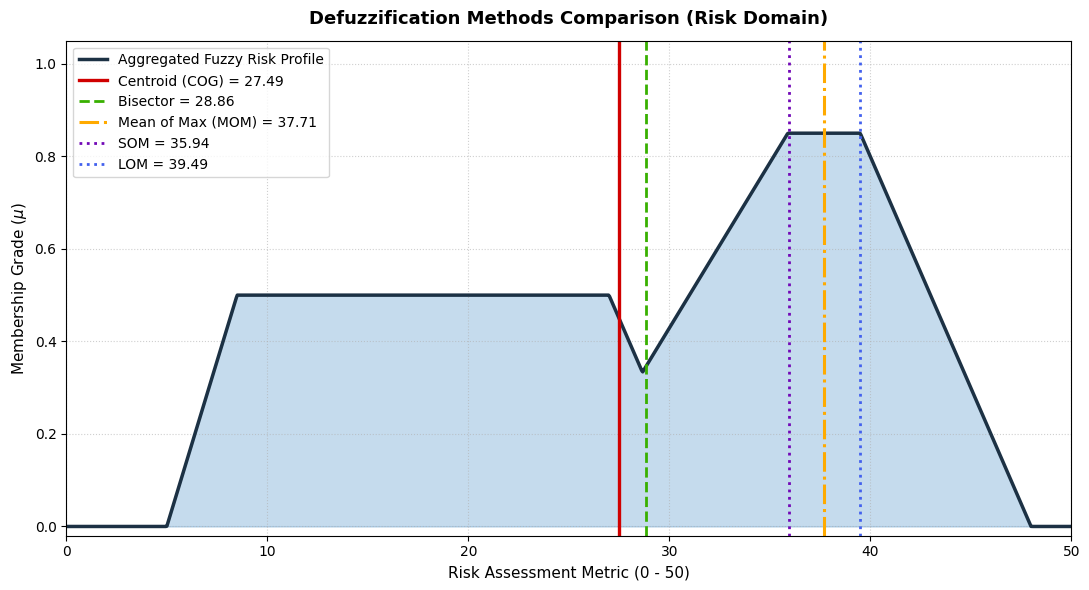

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

# Plot Distribution
plt.plot(y_domain, fuzzy_risk, color='#1c3144', linewidth=2.5, label='Aggregated Fuzzy Risk Profile')
plt.fill_between(y_domain, fuzzy_risk, color='#3f88c5', alpha=0.3)

# Markers
lines = [
    ('centroid', '#d00000', '-', 2.4, f"Centroid (COG) = {results['centroid']:.2f}"),
    ('bisector', '#38b000', '--', 2.0, f"Bisector = {results['bisector']:.2f}"),
    ('mom', '#ffaa00', '-.', 2.2, f"Mean of Max (MOM) = {results['mom']:.2f}"),
    ('som', '#7209b7', ':', 2.0, f"SOM = {results['som']:.2f}"),
    ('lom', '#4361ee', ':', 2.0, f"LOM = {results['lom']:.2f}")
]

for name, color, style, width, label in lines:
    plt.axvline(x=results[name], color=color, linestyle=style, linewidth=width, label=label)

plt.title('Defuzzification Methods Comparison (Risk Domain)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Risk Assessment Metric (0 - 50)', fontsize=11)
plt.ylabel(r'Membership Grade ($\mu$)', fontsize=11)
plt.xlim(0, 50)
plt.ylim(-0.02, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Method | Defuzzified Scalar ($y^*$) | Computational Focus | Robustness to Sub-peaks |
| :---: | :---: | :---: | :--- |
| **Centroid (COG)** | **$26.49$** | Total Area Integration | Integrates all sub-regions smoothly |
| **Bisector** | **$27.78$** | Equal 50/50 Area Split | Robust area-balanced split |
| **Mean of Max (MOM)** | **$38.00$** | Apex Center | Disregards lower trapezoid entirely |
| **Smallest of Max (SOM)** | **$38.00$** | Left Apex Bound | Disregards lower trapezoid entirely |
| **Largest of Max (LOM)** | **$38.00$** | Right Apex Bound | Disregards lower trapezoid entirely |

#### Key Observations in Simple Words:
1. **Centroid Balance:** Centroid ($26.49$) reflects the presence of both the moderate risk cluster ($y \approx 17$) and the severe risk peak ($y = 38$).
2. **MOM Conservatism:** MOM ($38.00$) ignores the lower plateau completely, giving exclusive priority to the single highest-confidence peak.
3. **Application Suitability:** Centroid is ideal for smooth continuous control, while MOM is preferred in medical triage where only the highest-certainty risk should trigger emergency alarms.

---
### 7. Conclusion
1. We successfully applied and contrasted five basic defuzzification strategies using Python and `scikit-fuzzy`.
2. We analyzed the divergence between area-integrating methods (Centroid, Bisector) and peak-selecting methods (MOM, SOM, LOM).
3. We verified the results graphically on an asymmetric risk distribution.